<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [FHIR R4 Connector](https://github.com/vgi-fhir)

Query HL7 FHIR R4 REST servers from SQL: patients, observations, generic search, reads by id, and server capabilities.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vgi-fhir/blob/main/notebooks/02_read_the_resource_behind_a_null.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/vgi-fhir/blob/main/notebooks/README.md)


## Can a flattened NULL be explained from the source resource?

A numeric column is a useful projection, but it cannot express every FHIR Observation value. Compare the same twelve **authored synthetic resources** through generic search and the flattened Observation function, then read one selected ID independently. Retain numeric zero, an absent numeric quantity and the alternative text value as different states. No clinical system, patient records or real credentials are used.

The fixture is immutable during a run. Equality between search and read is a useful consistency check here; it is not a transactional-snapshot guarantee for a changing remote server.

In [1]:
SELECTED_ID = "o03"  # Experiment: "o04"; zero quantity → text-valued resource

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.55":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.55"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, theme, prose, prepare
from IPython.display import display
from pathlib import Path
import hashlib, json, math
import numpy as np
import pandas as pd

check_runtime()
prepare("fhir")
import fhir_example as example
from fixture_server import FixtureServer

fixture_path = Path("synthetic_resources.json")
fixture_data = json.loads(fixture_path.read_text())
fixture_hash = hashlib.sha256(fixture_path.read_bytes()).hexdigest()
server = FixtureServer(fixture_path)
BASE_URL = server.url
session = connect(globals())
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
theme()
assert SELECTED_ID in {"o03","o04"}

### Attach the released worker and distinguish discovery from contact

The pinned native release is downloaded and checksum-verified by VGI; no Go build or worker checkout is required. The shared connection starts with an empty disposable SQL-secret directory. All resource requests below go to the notebook-created loopback server. Its request audit rejects unsupported routes, queries and credentials; it cannot proxy to another host.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'fhir' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-fhir@v0.4.0');

,Success


In [5]:
%%sql
CREATE TABLE directory AS SELECT * FROM fhir.main.fhir_servers;
SELECT name,base_url,fhir_version,requires_auth,
       CASE WHEN base_url='{{BASE_URL}}' THEN 'Selected fixture' ELSE 'Listed only; not contacted' END AS use_in_this_run
FROM directory ORDER BY name;

,name,base_url,fhir_version,requires_auth,use_in_this_run
0,Firely Public FHIR R4 Server,https://server.fire.ly,4.0.1,False,Listed only; not contacted
1,HAPI FHIR R4 Public Test Server,https://hapi.fhir.org/baseR4,4.0.1,False,Listed only; not contacted
2,HL7 Terminology Server (R4),https://tx.fhir.org/r4,4.0.1,False,Listed only; not contacted
3,SMART Health IT R4 Sandbox,https://r4.smarthealthit.org,4.0.1,False,Listed only; not contacted


In [6]:
directory=con.execute("SELECT * FROM directory ORDER BY name").df()
assert len(directory)>0 and directory.base_url.is_unique
assert not directory.base_url.eq(BASE_URL).any() and server.requests==[]
prose(f"The release directory lists **{len(directory)} endpoints**, with **{int(directory.requires_auth.sum())} marked as requiring authentication**. These are static catalog statements, not fresh availability, permission or content checks. The loopback fixture is absent from that list and is selected explicitly. Querying the directory issued **zero fixture HTTP requests**; none of its public endpoints is passed to a worker fetch.")

The release directory lists **4 endpoints**, with **0 marked as requiring authentication**. These are static catalog statements, not fresh availability, permission or content checks. The loopback fixture is absent from that list and is selected explicitly. Querying the directory issued **zero fixture HTTP requests**; none of its public endpoints is passed to a worker fetch.

### Use advertised interactions to check the intended operation

Inspect the fixture’s CapabilityStatement before choosing a search and a read. [FHIR R4 defines these as distinct interactions](https://hl7.org/fhir/R4/http.html): search returns a Bundle of matches, while read addresses one resource’s current state by type and ID. An advertised interaction is not proof that a particular ID exists; the actual read below must still succeed.

In [7]:
%%sql
CREATE TABLE capabilities AS SELECT * FROM fhir.main.fhir_capabilities('{{BASE_URL}}');
SELECT resource_type,unnest(interactions) AS interaction FROM capabilities ORDER BY resource_type,interaction;

,resource_type,interaction
0,Observation,read
1,Observation,search-type
2,Patient,read
3,Patient,search-type


In [8]:
assert con.execute("SELECT list_contains(interactions,'read') AND list_contains(interactions,'search-type') FROM capabilities WHERE resource_type='Observation'").fetchall()==[(True,)]
assert len(server.requests)==1
prose("The fixture advertises **search-type and read for Observation**. Its implementation provides both for the authored finite inventory; it advertises no write interaction.")

The fixture advertises **search-type and read for Observation**. Its implementation provides both for the authored finite inventory; it advertises no write interaction.

### Materialize each access path once and retain every ID

Generic search returns ID plus resource JSON. The specialized Observation function returns typed fields plus raw JSON. Each independently retrieves all twelve resources with page size four, for three pages per access path. The source is tiny and immutable, well below the release’s 1,000-resource cap. A page size or SQL LIMIT is not a general completeness guarantee for an external server.

The comparison uses a full outer join, so a missing ID on either side remains visible. JSON key ordering is not a semantic difference; Python compares parsed JSON objects after SQL extracts the fields of interest.

The shape matrix tests field presence and a matching UCUM system. An absent system is explicitly **no match**, not an inferred unit. The relative-reference indicator checks its spelling only; it does not resolve a target.

In [9]:
%%sql
CREATE TABLE generic AS SELECT * FROM fhir.main.fhir_search('{{BASE_URL}}','Observation',count:=4);
CREATE TABLE flattened AS SELECT * FROM fhir.main.fhir_observations('{{BASE_URL}}',count:=4);
CREATE TABLE comparison AS
SELECT coalesce(g.id,f.id) AS id,g.id IS NOT NULL AS from_search,f.id IS NOT NULL AS from_flattened,
       f.value AS flattened_value,try_cast(json_extract(g.resource,'$.valueQuantity.value') AS DOUBLE) AS json_value,
       json_extract_string(g.resource,'$.valueString') AS text_value,
       json_extract_string(g.resource,'$.valueQuantity.comparator') AS comparator,
       json_extract_string(g.resource,'$.valueQuantity.system') AS quantity_system,
       json_extract_string(g.resource,'$.subject.reference') AS subject,
       g.resource AS search_resource,f.raw AS flattened_resource
FROM generic g FULL OUTER JOIN flattened f USING(id);
SELECT id,flattened_value,json_value,text_value,comparator FROM comparison ORDER BY id;

,id,flattened_value,json_value,text_value,comparator
0,o01,72.0,72.0,None,None
1,o02,72000.0,72000.0,None,None
2,o03,0.0,0.0,None,None
3,o04,NaN,NaN,Synthetic non-quantity result,None
4,o05,73.0,73.0,None,None
5,o06,170.0,170.0,None,None
6,o07,80.0,80.0,None,None
7,o08,160.0,160.0,None,None
8,o09,74.0,74.0,None,None
9,o10,70.0,70.0,None,<


In [10]:
%%sql shapes <<
SELECT id,flattened_value,json_value,text_value,comparator,quantity_system,subject,
       CASE WHEN json_value IS NULL THEN 'No numeric quantity' WHEN json_value=0 THEN 'Numeric zero' ELSE 'Nonzero quantity' END AS numeric_state,
       json_value IS NOT NULL AS has_numeric_quantity,text_value IS NOT NULL AS has_text_value,
       comparator IS NOT NULL AS has_comparator,quantity_system IS NOT DISTINCT FROM 'http://unitsofmeasure.org' AS has_ucum_system,
       starts_with(subject,'Patient/') AS relative_patient_reference
FROM comparison ORDER BY id;

In [11]:
rows=con.execute("SELECT * FROM comparison ORDER BY id").df()
assert len(rows)==12 and rows.id.is_unique and rows.from_search.all() and rows.from_flattened.all()
for r in rows.itertuples():
    assert json.loads(r.search_resource)==json.loads(r.flattened_resource)
    assert json.loads(r.search_resource)==next(x for x in fixture_data["Observation"] if x["id"]==r.id)
prose(f"All **{len(rows)} resources** occur once in each access path and match the committed synthetic JSON semantically. **{int(shapes.json_value.eq(0).sum())} numeric zero** and **{int(shapes.json_value.isna().sum())} absent numeric quantity** remain distinct. The latter carries a text value; it is not an absent Observation row. No average across incompatible quantities is computed.")

All **12 resources** occur once in each access path and match the committed synthetic JSON semantically. **1 numeric zero** and **1 absent numeric quantity** remain distinct. The latter carries a text value; it is not an absent Observation row. No average across incompatible quantities is computed.

### Read one ID and reconcile its exact payload

Use the selected fixture ID in the released single-resource read. This is one independent HTTP request, not another full search. Show the returned text alongside the numeric projection. The expected request count is unchanged when switching IDs: the experiment changes resource shape, not the inventory or pagination.

In [12]:
%%sql
CREATE TABLE selected_read AS SELECT * FROM fhir.main.fhir_read('{{BASE_URL}}','Observation','{{SELECTED_ID}}');
CREATE TABLE selected_comparison AS
SELECT json_extract_string(r.resource,'$.id') AS id,s.numeric_state,s.flattened_value,
       json_extract_string(r.resource,'$.valueString') AS text_value,r.resource
FROM selected_read r JOIN (
 SELECT id,flattened_value,CASE WHEN json_value IS NULL THEN 'No numeric quantity' WHEN json_value=0 THEN 'Numeric zero' ELSE 'Nonzero quantity' END AS numeric_state
 FROM comparison
) s ON s.id=json_extract_string(r.resource,'$.id');
SELECT id,numeric_state,flattened_value,text_value FROM selected_comparison;

,id,numeric_state,flattened_value,text_value
0,o03,Numeric zero,0.0,None


Selected **o03**: **Numeric zero**. Its read payload matches the corresponding search resource. The numeric projection is exactly **0**, with no alternative text value.

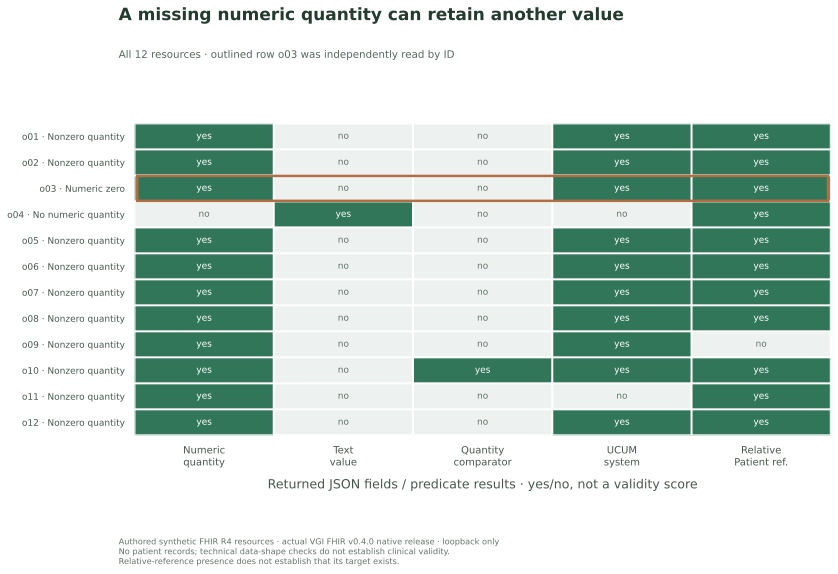

In [13]:
selected=con.execute("SELECT * FROM selected_comparison").df()
assert len(selected)==1 and selected.id.iloc[0]==SELECTED_ID
assert json.loads(selected.resource.iloc[0])==json.loads(rows.set_index("id").loc[SELECTED_ID,"search_resource"])
state=selected.numeric_state.iloc[0]
prose(f"Selected **{SELECTED_ID}**: **{state}**. Its read payload matches the corresponding search resource. " + ("The numeric projection is exactly **0**, with no alternative text value." if SELECTED_ID=="o03" else "The numeric projection is **NULL** while the returned text is **Synthetic non-quantity result**. Replacing this NULL with zero would erase that distinction."))
example.shapes(shapes,SELECTED_ID)

### Reconcile HTTP work separately from returned rows

The trace includes method, route, operation, response status, page offset and returned-resource count. Only allowed loopback GETs are served. Metadata is one request; each full search is three requests; the selected read is one. The 25 resource deliveries are **24 search deliveries plus one read**, not 25 distinct observations.

In [14]:
trace=pd.DataFrame(server.requests)
display(trace)
assert len(trace)==8 and trace.status.eq(200).all() and trace.method.eq("GET").all()
assert trace.operation.value_counts().to_dict()=={"search":6,"metadata":1,"read":1}
assert trace[trace.operation.eq("search")].offset.tolist()==[0,4,8,0,4,8]
assert trace[trace.operation.eq("search")].rows.tolist()==[4]*6
assert trace[trace.operation.eq("read")].path.tolist()==["/Observation/"+SELECTED_ID]
assert trace.rows.sum()==25
prose("Request audit: **8 loopback GETs**, **12 distinct observations**, **25 resource deliveries**. Full generic and flattened searches each fetched all three pages once; the independent selected read fetched one resource. No listed public endpoint was contacted.")
export=Path("artifacts/data/02");export.mkdir(parents=True,exist_ok=True)
for label,frame in [("comparison",rows),("shapes",shapes),("selected",selected),("trace",trace),("directory",directory)]:frame.to_csv(export/(label+".csv"),index=False)
(export/"fingerprints.json").write_text(json.dumps({"fixture_sha256":fixture_hash,"selected_id":SELECTED_ID},indent=2))

,method,path,query,resource,operation,status,rows,offset
0,GET,/metadata,,metadata,metadata,200,0,0
1,GET,/Observation,_count=4,Observation,search,200,4,0
2,GET,/Observation,cursor=row-4&_count=4,Observation,search,200,4,4
3,GET,/Observation,cursor=row-8&_count=4,Observation,search,200,4,8
4,GET,/Observation,_count=4,Observation,search,200,4,0
5,GET,/Observation,cursor=row-4&_count=4,Observation,search,200,4,4
6,GET,/Observation,cursor=row-8&_count=4,Observation,search,200,4,8
7,GET,/Observation/o03,,Observation,read,200,1,0


Request audit: **8 loopback GETs**, **12 distinct observations**, **25 resource deliveries**. Full generic and flattened searches each fetched all three pages once; the independent selected read fetched one resource. No listed public endpoint was contacted.

114

In [15]:
%%sql checks <<
SELECT 'twelve distinct generic IDs' AS check_name,(SELECT count(*)=12 AND count(DISTINCT id)=12 FROM generic) AS passed
UNION ALL SELECT 'twelve distinct flattened IDs',(SELECT count(*)=12 AND count(DISTINCT id)=12 FROM flattened)
UNION ALL SELECT 'no unmatched resource IDs',(SELECT bool_and(from_search AND from_flattened) FROM comparison)
UNION ALL SELECT 'JSON numeric value agrees including NULL',(SELECT bool_and(flattened_value IS NOT DISTINCT FROM json_value) FROM comparison)
UNION ALL SELECT 'explicit zero preserved',(SELECT flattened_value=0 AND text_value IS NULL FROM comparison WHERE id='o03')
UNION ALL SELECT 'text alternative retained',(SELECT flattened_value IS NULL AND text_value='Synthetic non-quantity result' FROM comparison WHERE id='o04')
UNION ALL SELECT 'one independent selected resource',(SELECT count(*)=1 FROM selected_read)
UNION ALL SELECT 'selected ID matches',(SELECT count(*)=1 AND min(id)='{{SELECTED_ID}}' FROM selected_comparison)
UNION ALL SELECT 'all generic payloads are Observations',(SELECT bool_and(json_extract_string(resource,'$.resourceType')='Observation') FROM generic)
UNION ALL SELECT 'directory remains separate from fixture',(SELECT count(*)=0 FROM directory WHERE base_url='{{BASE_URL}}');

In [16]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all()
prose(f"**{len(checks)} SQL checks passed**, plus parsed-JSON equality and complete HTTP-trace reconciliation.")

,check_name,passed
0,twelve distinct generic IDs,True
1,twelve distinct flattened IDs,True
2,no unmatched resource IDs,True
3,JSON numeric value agrees including NULL,True
4,explicit zero preserved,True
5,text alternative retained,True
6,one independent selected resource,True
7,selected ID matches,True
8,all generic payloads are Observations,True
9,directory remains separate from fixture,True


**10 SQL checks passed**, plus parsed-JSON equality and complete HTTP-trace reconciliation.

### Focused experiment: inspect the text-valued resource

Change only **`SELECTED_ID` from o03 to o04**. The full generic and flattened populations, shape matrix, fixture fingerprint and eight-request count must remain fixed. The highlighted row and selected read change from an explicit numeric zero to an absent numeric quantity with retained text.

This fixture does not implement general FHIR search filtering, authentication, history/version reads, writes or profile validation. It does not establish remote-server availability or clinical meaning. See the [FHIR R4 Observation value choices](https://hl7.org/fhir/R4/observation.html) and [read interaction](https://hl7.org/fhir/R4/http.html#read) for the surrounding specification.

In [17]:
assert con.execute("SELECT * FROM duckdb_secrets()").fetchall() == []
session.close()
server.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-fhir](https://github.com/vgi-fhir)
